








1.Knn (from scratch):
Write your own knn model for classification. 
Compare your results with those from the same model using scikit-learn on the IRIS dataset.

In [172]:
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from collections import Counter

In [173]:
# Load the Iris dataset
iris = load_iris()
X = iris.data
y = iris.target

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3,random_state=42)
print(f"Training data shape: {X_train.shape}")
print(f"Testing data shape: {X_test.shape}")

Training data shape: (105, 4)
Testing data shape: (45, 4)


In [174]:
def euclidean_distance(x1, x2):
    return np.sqrt(np.sum((x1 - x2)**2))

def predict_custom_knn(X_train, y_train, X_test_point, k):
    distances = [euclidean_distance(X_test_point, x_train) for x_train in X_train]

    # Get the k nearest neighbors' indices
    k_nearest_indices = np.argsort(distances)[:k]

    # Get the labels of the k nearest neighbors
    k_nearest_labels = [y_train[i] for i in k_nearest_indices]

    # Return the most common class label
    most_common = Counter(k_nearest_labels).most_common(1)
    return most_common[0][0]

def custom_knn_predict(X_train, y_train, X_test, k):
    predictions = [predict_custom_knn(X_train, y_train, x_test_point, k) for x_test_point in X_test]
    return np.array(predictions)

# Set the value of K
k_value = 5

# Make predictions using our custom KNN
y_pred_custom = custom_knn_predict(X_train, y_train, X_test, k_value)

# Calculate accuracy for custom KNN
accuracy_custom = accuracy_score(y_test, y_pred_custom)
print(f"Custom KNN Accuracy (k={k_value}): {accuracy_custom:.4f}")

Custom KNN Accuracy (k=5): 1.0000


In [175]:
from sklearn.neighbors import KNeighborsClassifier

# Initialize and train the scikit-learn KNN classifier
knn_sklearn = KNeighborsClassifier(n_neighbors=k_value)
knn_sklearn.fit(X_train, y_train)

# Make predictions using scikit-learn KNN
y_pred_sklearn = knn_sklearn.predict(X_test)

# Calculate accuracy for scikit-learn KNN
accuracy_sklearn = accuracy_score(y_test, y_pred_sklearn)
print(f"Scikit-learn KNN Accuracy (k={k_value}): {accuracy_sklearn:.4f}")

print("\n--- Comparison ---")
print(f"Custom KNN Accuracy: {accuracy_custom:.4f}")
print(f"Scikit-learn KNN Accuracy: {accuracy_sklearn:.4f}")

Scikit-learn KNN Accuracy (k=5): 1.0000

--- Comparison ---
Custom KNN Accuracy: 1.0000
Scikit-learn KNN Accuracy: 1.0000


2.Use M-fold cross validation to find the oprtimal value of K

In [176]:
from sklearn.model_selection import StratifiedKFold

# Define a range of m values to test
m_values_to_test = range(1,21)

n_splits = 5
skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)

m_accuracies = {}

print(f"Performing {n_splits}-fold cross-validation for m values from {min(m_values_to_test)} to {max(m_values_to_test)}...")

Performing 5-fold cross-validation for m values from 1 to 20...


In [177]:
for m in m_values_to_test:
    fold_accuracies = []
    for fold, (train_index, val_index) in enumerate(skf.split(X, y)):
        X_train_fold, X_val_fold = X[train_index], X[val_index]
        y_train_fold, y_val_fold = y[train_index], y[val_index]

        # Make predictions using our custom KNN for the current fold and m
        y_pred_fold = custom_knn_predict(X_train_fold, y_train_fold, X_val_fold, m)

        # Calculate accuracy for the current fold
        accuracy_fold = accuracy_score(y_val_fold, y_pred_fold)
        fold_accuracies.append(accuracy_fold)

    # Store the average accuracy for the current m
    m_accuracies[m] = np.mean(fold_accuracies)
    print(f"  M = {m}: Average Accuracy = {m_accuracies[m]:.4f}")

# Find the optimal m value
optimal_m = max(m_accuracies, key=m_accuracies.get)
print(f"\nOptimal  value found: {optimal_m} with an average accuracy of {m_accuracies[optimal_m]:.4f}")

  M = 1: Average Accuracy = 0.9533
  M = 2: Average Accuracy = 0.9533
  M = 3: Average Accuracy = 0.9533
  M = 4: Average Accuracy = 0.9533
  M = 5: Average Accuracy = 0.9667
  M = 6: Average Accuracy = 0.9667
  M = 7: Average Accuracy = 0.9600
  M = 8: Average Accuracy = 0.9600
  M = 9: Average Accuracy = 0.9600
  M = 10: Average Accuracy = 0.9600
  M = 11: Average Accuracy = 0.9733
  M = 12: Average Accuracy = 0.9667
  M = 13: Average Accuracy = 0.9733
  M = 14: Average Accuracy = 0.9733
  M = 15: Average Accuracy = 0.9800
  M = 16: Average Accuracy = 0.9733
  M = 17: Average Accuracy = 0.9800
  M = 18: Average Accuracy = 0.9667
  M = 19: Average Accuracy = 0.9733
  M = 20: Average Accuracy = 0.9733

Optimal  value found: 15 with an average accuracy of 0.9800


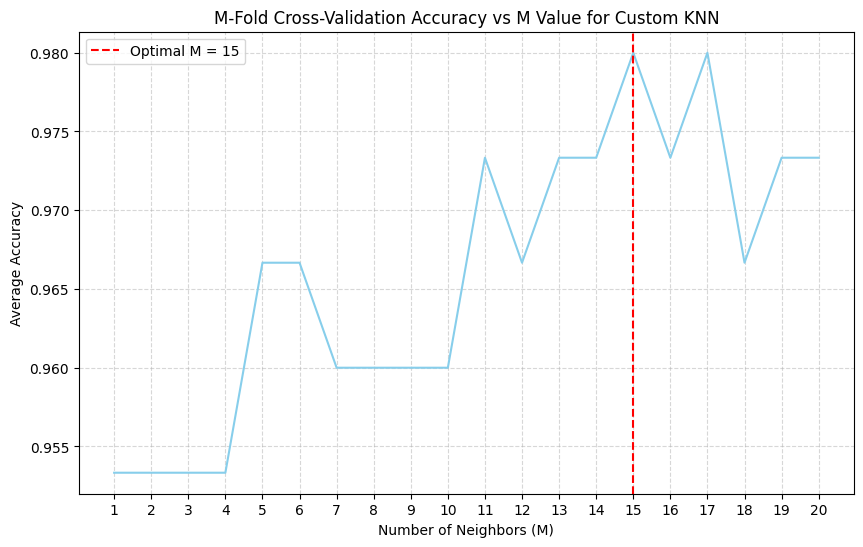

In [178]:
import matplotlib.pyplot as plt

# Plotting the results
plt.figure(figsize=(10, 6))
plt.plot(list(m_accuracies.keys()), list(m_accuracies.values()), linestyle='-', color='skyblue')
plt.title('M-Fold Cross-Validation Accuracy vs M Value for Custom KNN')
plt.xlabel('Number of Neighbors (M)')
plt.ylabel('Average Accuracy')
plt.xticks(list(m_values_to_test))
plt.grid(True, linestyle='--', alpha=0.5)
plt.axvline(x=optimal_m, color='red', linestyle='--', label=f'Optimal M = {optimal_m}')
plt.legend()
plt.show()